# 🎓 Student Expense Tracker: Exploratory Data Analysis (EDA)

**Author:** Thanishka  
**Project:** Student Expense Tracker  
**Domain:** Personal Finance & Student Spending Analytics  

### Objective
This project examines college students' personal financial behaviors to understand:
1. Where student allowances and income actually go across primary expense categories.
2. Monthly spending fluctuations, especially during exams, campus fests, and holidays.
3. Adoption of digital payment methods (UPI, Cards, Cash).
4. Budget compliance—identifying how frequently students exceed monthly allowances and by how much.
5. Actionable financial habits students can build to stay within budget.

### Dataset Information
- **Source:** Synthetic dataset (`data/student_expenses.csv`) specifically curated to reflect authentic Indian college student spending patterns.
- **Records:** 520 expense entries spanning 15 students over a 6-month period (January 2024 to June 2024).
- **Attributes:** `Student ID`, `Date`, `Category`, `Amount`, `Payment Method`, `Monthly Budget`, and `Student Year`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configure display and plotting styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Environment configured successfully!")

Environment configured successfully!


---
## 1. Data Ingestion & Inspection

We load the dataset from `../data/student_expenses.csv` and inspect its initial rows, shape, column data types, and non-null counts.

In [2]:
DATA_PATH = os.path.join("..", "data", "student_expenses.csv")
df = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("First 5 records:")
display_df = df.head(5)
print(display_df.to_string(index=False))

print("\nData Types and Non-Null Summary:")
df.info()

Dataset Shape: 520 rows, 7 columns

First 5 records:
Student ID       Date      Category  Amount Payment Method  Monthly Budget Student Year
    STU101 2024-01-01          Food     116            UPI            8000     1st Year
    STU114 2024-01-01     Education    2372            UPI            9000     4th Year
    STU114 2024-01-01          Food     202           Cash            9000     4th Year
    STU112 2024-01-02 Entertainment     338           Cash           13000     4th Year
    STU105 2024-01-03     Education     350           Card            8000     2nd Year

Data Types and Non-Null Summary:
<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Student ID      520 non-null    str  
 1   Date            520 non-null    str  
 2   Category        520 non-null    str  
 3   Amount          520 non-null    int64
 4   Payment Method  520 non-null 

---
## 2. Data Cleaning & Feature Engineering

Clean data is the foundation of dependable analysis. Here we:
- Verify and handle missing values (`isnull().sum()`).
- Detect and eliminate duplicate entries (`duplicated().sum()`).
- Convert the `Date` column from string format to pandas datetime format.
- Engineer time-based attributes: `Month` (YYYY-MM), `Month_Name`, and `Day_of_Week`.

In [3]:
# 1. Missing Values Check
missing = df.isnull().sum()
print("Missing values per column:\n", missing)

# 2. Duplicate Records Check
duplicates = df.duplicated().sum()
print(f"\nDuplicate rows found: {duplicates}")

# 3. Convert Date to Datetime
df['Date'] = pd.to_datetime(df['Date'])

# 4. Feature Engineering
df['Month'] = df['Date'].dt.strftime('%Y-%m')
df['Month_Name'] = df['Date'].dt.strftime('%B %Y')
df['Day_of_Week'] = df['Date'].dt.day_name()

print(f"\nCleaned data range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
print(f"Unique students: {df['Student ID'].nunique()}")
print(df[['Student ID', 'Date', 'Month', 'Day_of_Week', 'Category', 'Amount']].head())

Missing values per column:
Student ID        0
Date              0
Category          0
Amount            0
Payment Method    0
Monthly Budget    0
Student Year      0
dtype: int64

Duplicate rows found: 0

Cleaned data range: 2024-01-01 to 2024-06-30
Unique students: 15
  Student ID       Date    Month Day_of_Week   Category  Amount
0     STU101 2024-01-01  2024-01      Monday       Food     202
1     STU110 2024-01-01  2024-01      Monday       Food     311
2     STU114 2024-01-01  2024-01      Monday  Transport      86
3     STU109 2024-01-03  2024-01   Wednesday       Food     170
4     STU111 2024-01-03  2024-01   Wednesday  Education     927


---
## 3. Core Summary Statistics

We calculate key summary indicators including total student spending, transaction volume, average and median transaction size, and overall budget utilization.

In [4]:
total_spending = df['Amount'].sum()
total_transactions = len(df)
avg_transaction = df['Amount'].mean()
median_transaction = df['Amount'].median()
min_transaction = df['Amount'].min()
max_transaction = df['Amount'].max()

# Total budget across all active student-months
monthly_student_budget = df.groupby(['Month', 'Student ID', 'Monthly Budget'])['Amount'].sum().reset_index()
total_budget_allocated = monthly_student_budget['Monthly Budget'].sum()
overall_utilization = (total_spending / total_budget_allocated) * 100

print(f"{'Metric':<30} | {'Value'}")
print("-" * 50)
print(f"{'Total Student Spending':<30} | INR {total_spending:,.2f}")
print(f"{'Total Number of Transactions':<30} | {total_transactions:,}")
print(f"{'Average Expense per Txn':<30} | INR {avg_transaction:,.2f}")
print(f"{'Median Expense per Txn':<30} | INR {median_transaction:,.2f}")
print(f"{'Smallest Expense':<30} | INR {min_transaction:,.2f}")
print(f"{'Largest Expense':<30} | INR {max_transaction:,.2f}")
print(f"{'Total Budget Allocated':<30} | INR {total_budget_allocated:,.2f}")
print(f"{'Overall Budget Utilization':<30} | {overall_utilization:.2f}%")

Metric                         | Value
--------------------------------------------------
Total Student Spending         | INR 411,464.00
Total Number of Transactions   | 520
Average Expense per Txn        | INR 791.28
Median Expense per Txn         | INR 453.00
Smallest Expense               | INR 39.00
Largest Expense                | INR 4,103.00
Total Budget Allocated         | INR 858,000.00
Overall Budget Utilization     | 47.96%


---
## 4. Spending by Category

To understand where money flows, we analyze spending totals, transaction counts, average ticket sizes, and percentage shares for each expense category:
- **Food**
- **Transport**
- **Education**
- **Shopping**
- **Entertainment**
- **Bills and Other**

Category Spending Summary:
       Category  Total_Amount  Transaction_Count  Average_Amount  Percentage_Share
       Shopping        138747                 70         1982.10             33.72
      Education         83611                 63         1327.16             20.32
Bills and Other         59767                 53         1127.68             14.53
           Food         55670                165          337.39             13.53
  Entertainment         52224                 68          768.00             12.69
      Transport         21445                101          212.33              5.21


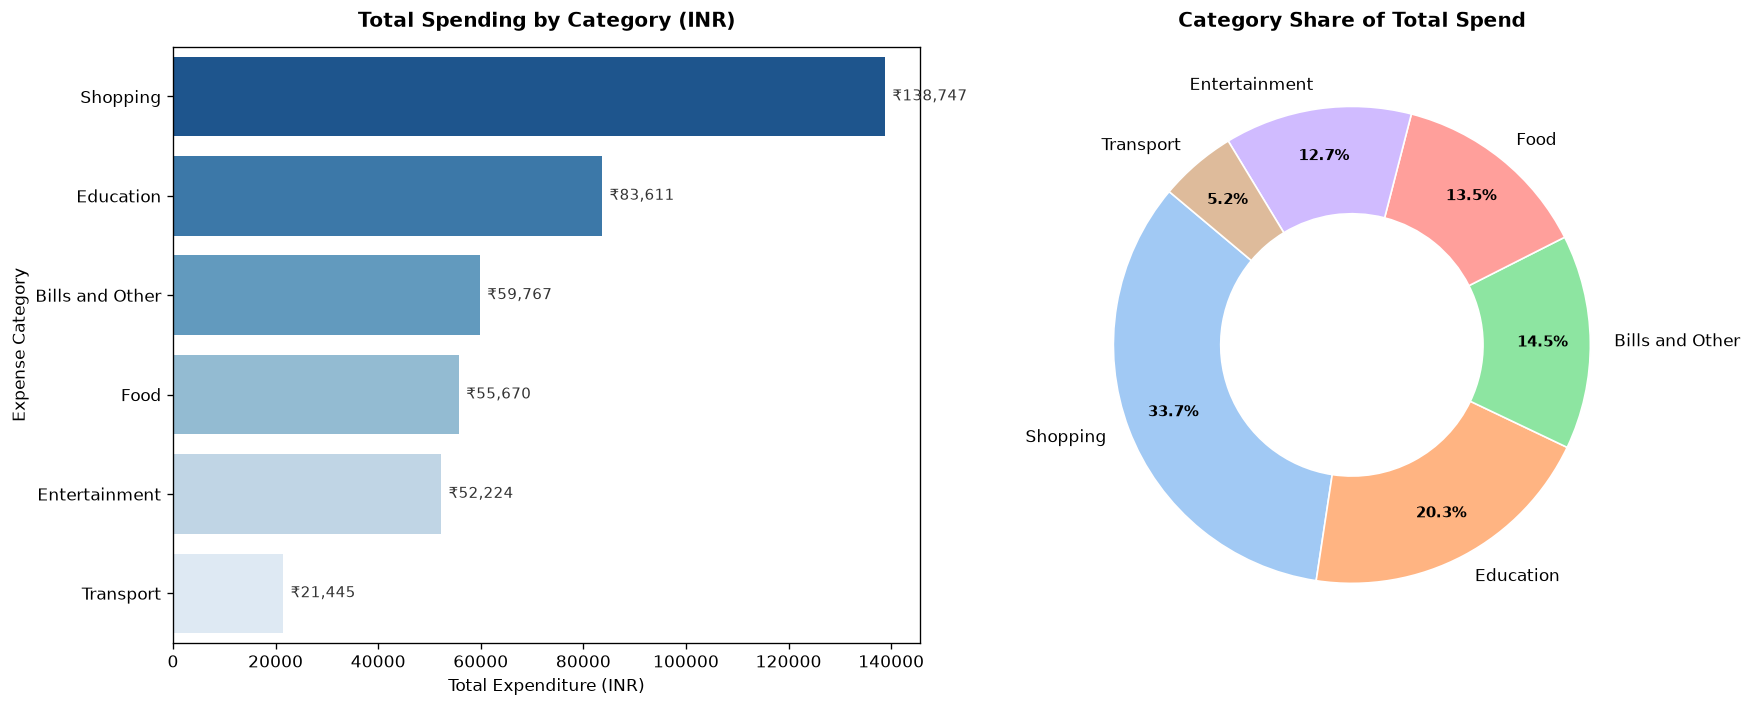

In [5]:
# Category Aggregation
cat_df = df.groupby('Category').agg(
    Total_Amount=('Amount', 'sum'),
    Transaction_Count=('Amount', 'count'),
    Average_Amount=('Amount', 'mean')
).reset_index()

cat_df['Percentage_Share'] = ((cat_df['Total_Amount'] / total_spending) * 100).round(2)
cat_df['Average_Amount'] = cat_df['Average_Amount'].round(2)
cat_df = cat_df.sort_values(by='Total_Amount', ascending=False).reset_index(drop=True)

print("Category Spending Summary:")
print(cat_df.to_string(index=False))

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Bar Chart
sns.barplot(
    data=cat_df, 
    x='Total_Amount', 
    y='Category', 
    palette='Blues_r', 
    ax=ax1, 
    hue='Category', 
    legend=False
)
ax1.set_title("Total Spending by Category (INR)", weight='bold', pad=12)
ax1.set_xlabel("Total Expenditure (INR)")
ax1.set_ylabel("Expense Category")
for p in ax1.patches:
    val = f"₹{int(p.get_width()):,}"
    ax1.annotate(val, (p.get_width() + 1500, p.get_y() + p.get_height() / 2),
                 ha='left', va='center', fontsize=9, color='#333333')

# Donut Chart
colors = sns.color_palette('pastel')[0:len(cat_df)]
wedges, texts, autotexts = ax2.pie(
    cat_df['Total_Amount'], 
    labels=cat_df['Category'], 
    autopct='%1.1f%%',
    startangle=140, 
    colors=colors,
    pctdistance=0.8,
    wedgeprops=dict(width=0.45, edgecolor='w')
)
for at in autotexts:
    at.set_fontsize(9)
    at.set_weight('bold')
ax2.set_title("Category Share of Total Spend", weight='bold', pad=12)

plt.tight_layout()
plt.show()

> **Key Category Insights:**
> 1. **Shopping (33.72%)** and **Education (20.32%)** are the highest spending categories by value, accounting for over **54%** of total expenditures.
> 2. **Food** is by far the most frequent expense category with **165 transactions** (nearly 32% of all transactions), but has a moderate average ticket size of **₹337.39**.
> 3. **Transport** represents regular daily commutes (metro/bus/autos) with the lowest average transaction cost of **₹212.33**.

---
## 5. Monthly Spending Trends

Here we examine the month-by-month trajectory to identify peak spending periods, seasonal patterns, and differences between semester phases.

Monthly Spending Breakdown:
  Month  Total_Amount  Transaction_Count  Average_Amount
2024-01         58322                 90          648.02
2024-02         59624                 82          727.12
2024-03        115284                 97         1188.49
2024-04         61858                 83          745.28
2024-05         60477                 85          711.49
2024-06         55899                 83          673.48

Highest Spending Month: 2024-03 with INR 115,284.00
Lowest Spending Month:  2024-06 with INR 55,899.00


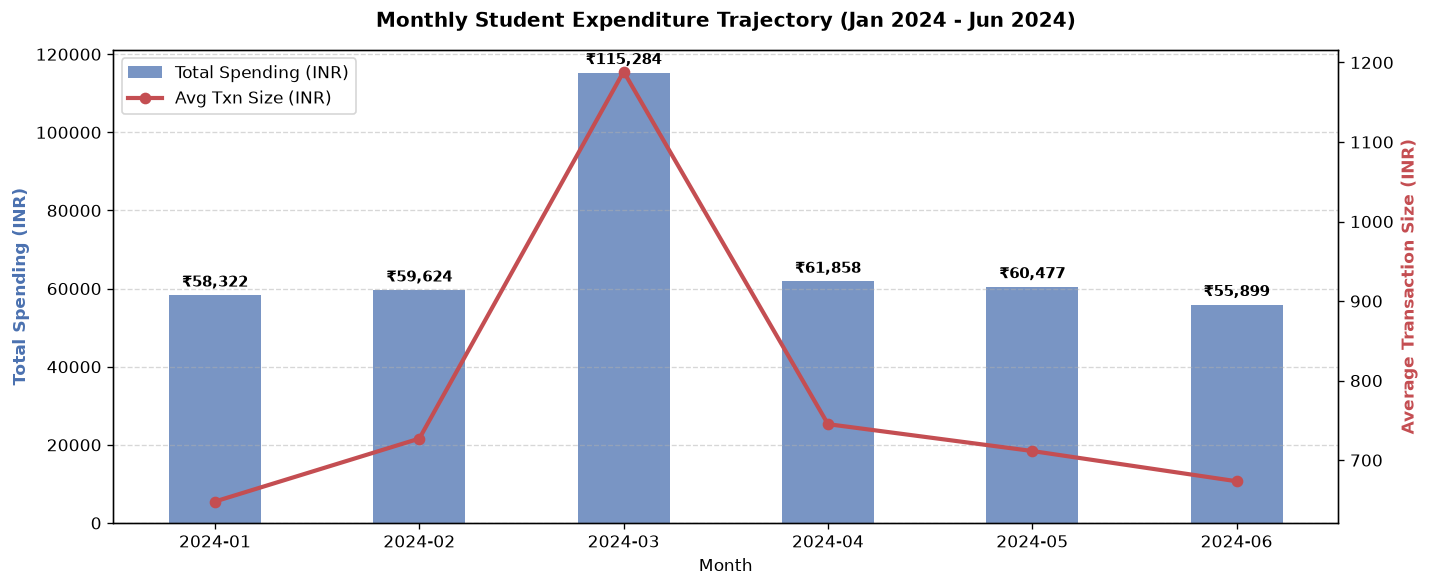

In [6]:
# Monthly Aggregation
monthly_df = df.groupby('Month').agg(
    Total_Amount=('Amount', 'sum'),
    Transaction_Count=('Amount', 'count'),
    Average_Amount=('Amount', 'mean')
).reset_index()

monthly_df['Average_Amount'] = monthly_df['Average_Amount'].round(2)

highest_month = monthly_df.loc[monthly_df['Total_Amount'].idxmax()]
lowest_month = monthly_df.loc[monthly_df['Total_Amount'].idxmin()]

print("Monthly Spending Breakdown:")
print(monthly_df.to_string(index=False))
print(f"\nHighest Spending Month: {highest_month['Month']} with INR {highest_month['Total_Amount']:,.2f}")
print(f"Lowest Spending Month:  {lowest_month['Month']} with INR {lowest_month['Total_Amount']:,.2f}")

# Visualization: Line & Bar Trend
fig, ax = plt.subplots(figsize=(12, 5))

# Bar for total amount
bars = ax.bar(monthly_df['Month'], monthly_df['Total_Amount'], color='#4C72B0', alpha=0.75, width=0.45, label='Total Spending (INR)')
ax.set_ylabel("Total Spending (INR)", color='#4C72B0', weight='bold')
ax.set_xlabel("Month")
ax.set_title("Monthly Student Expenditure Trajectory (Jan 2024 - Jun 2024)", weight='bold', pad=14)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate bars
for b in bars:
    height = b.get_height()
    ax.annotate(f"₹{int(height):,}",
                (b.get_x() + b.get_width() / 2, height),
                ha='center', va='bottom', fontsize=9, weight='bold', xytext=(0, 3),
                textcoords='offset points')

# Overlay line for average transaction size
ax2 = ax.twinx()
line = ax2.plot(monthly_df['Month'], monthly_df['Average_Amount'], color='#C44E52', marker='o', linewidth=2.5, label='Avg Txn Size (INR)')
ax2.set_ylabel("Average Transaction Size (INR)", color='#C44E52', weight='bold')
ax2.grid(False)

# Combined legend
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

> **Key Monthly Trend Insights:**
> 1. **March 2024** experienced a major expenditure spike (**₹115,284.00**, representing nearly 28% of all spending across the 6-month window). This correlates with college annual fest season, cultural events, and midterm project submissions.
> 2. Average ticket size also peaked in March at **₹1,188.49** per transaction (nearly 50% higher than the 6-month average).
> 3. **June 2024** marked the lowest spending month (**₹55,899.00**) as students completed exams and returned home for summer break.

---
## 6. Payment Method Analysis

We assess how students settle their transactions:
- **UPI (Unified Payments Interface):** Google Pay, PhonePe, Paytm, etc.
- **Card:** Debit / Credit cards.
- **Cash:** Physical currency.

Payment Method Summary:
Payment Method  Total_Amount  Transaction_Count  Average_Amount  Transaction_Share  Spending_Share
           UPI        247558                325          761.72              62.50           60.17
          Card        102319                 85         1203.75              16.35           24.87
          Cash         61587                110          559.88              21.15           14.97


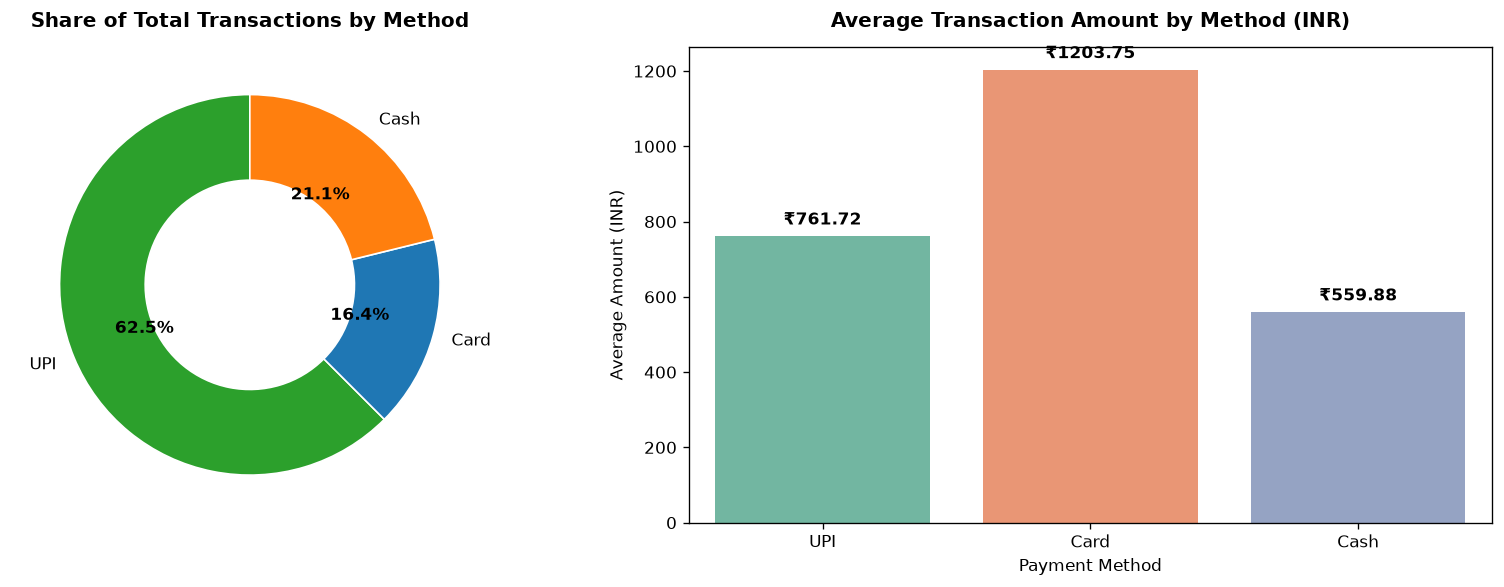

In [7]:
# Payment Aggregation
pay_df = df.groupby('Payment Method').agg(
    Total_Amount=('Amount', 'sum'),
    Transaction_Count=('Amount', 'count'),
    Average_Amount=('Amount', 'mean')
).reset_index()

pay_df['Transaction_Share'] = ((pay_df['Transaction_Count'] / total_transactions) * 100).round(2)
pay_df['Spending_Share'] = ((pay_df['Total_Amount'] / total_spending) * 100).round(2)
pay_df['Average_Amount'] = pay_df['Average_Amount'].round(2)
pay_df = pay_df.sort_values(by='Total_Amount', ascending=False).reset_index(drop=True)

print("Payment Method Summary:")
print(pay_df.to_string(index=False))

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Donut Chart for Transaction Share
colors_pay = ['#2ca02c', '#1f77b4', '#ff7f0e']
wedges, texts, autotexts = ax1.pie(
    pay_df['Transaction_Share'],
    labels=pay_df['Payment Method'],
    autopct='%1.1f%%',
    startangle=90,
    colors=colors_pay,
    wedgeprops=dict(width=0.45, edgecolor='w')
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_weight('bold')
ax1.set_title("Share of Total Transactions by Method", weight='bold', pad=12)

# Bar chart of Average Transaction Size
sns.barplot(data=pay_df, x='Payment Method', y='Average_Amount', palette='Set2', ax=ax2, hue='Payment Method', legend=False)
ax2.set_title("Average Transaction Amount by Method (INR)", weight='bold', pad=12)
ax2.set_ylabel("Average Amount (INR)")
ax2.set_xlabel("Payment Method")
for p in ax2.patches:
    ax2.annotate(f"₹{p.get_height():.2f}",
                 (p.get_x() + p.get_width() / 2, p.get_height() + 20),
                 ha='center', va='bottom', fontsize=10, weight='bold')

plt.tight_layout()
plt.show()

> **Key Payment Method Insights:**
> 1. **UPI dominates everyday life:** 62.5% of all transactions and 60.17% of total spending occur via UPI apps (canteen snacks, quick groceries, local autos, and recharges).
> 2. **Card for large purchases:** Cards represent only 16.35% of transactions but boast the highest average transaction size (**₹1,203.75**), primarily used for high-value clothing shopping, electronics, and course fees.
> 3. **Cash persists for petty expenses:** Cash is utilized for 21.15% of transactions with an average ticket of ₹559.88.

---
## 7. Budget vs. Actual Spending & Overrun Analysis

Budget compliance is the core metric of personal financial health. We calculate monthly budget versus actual expenses per student, detect overspending occurrences, and quantify overruns.

Monthly Budget vs Actual Totals:
  Month  Total_Budget  Total_Spent  Over_Budget_Students  Overall_Utilization_%
2024-01        143000        58322                     1                  40.78
2024-02        143000        59624                     1                  41.70
2024-03        143000       115284                     4                  80.62
2024-04        143000        61858                     0                  43.26
2024-05        143000        60477                     1                  42.29
2024-06        143000        55899                     0                  39.09

Total Student-Month Over-Budget Incidents: 7

Detailed Over-Budget Records:
  Month Student ID Student Year  Monthly Budget  Actual_Spent  Overspend_Amount  Budget_Utilization
2024-03     STU110     3rd Year            7000         15477              8477              221.10
2024-03     STU108     3rd Year           11000         16293              5293              148.12
2024-05     STU102     1st Yea

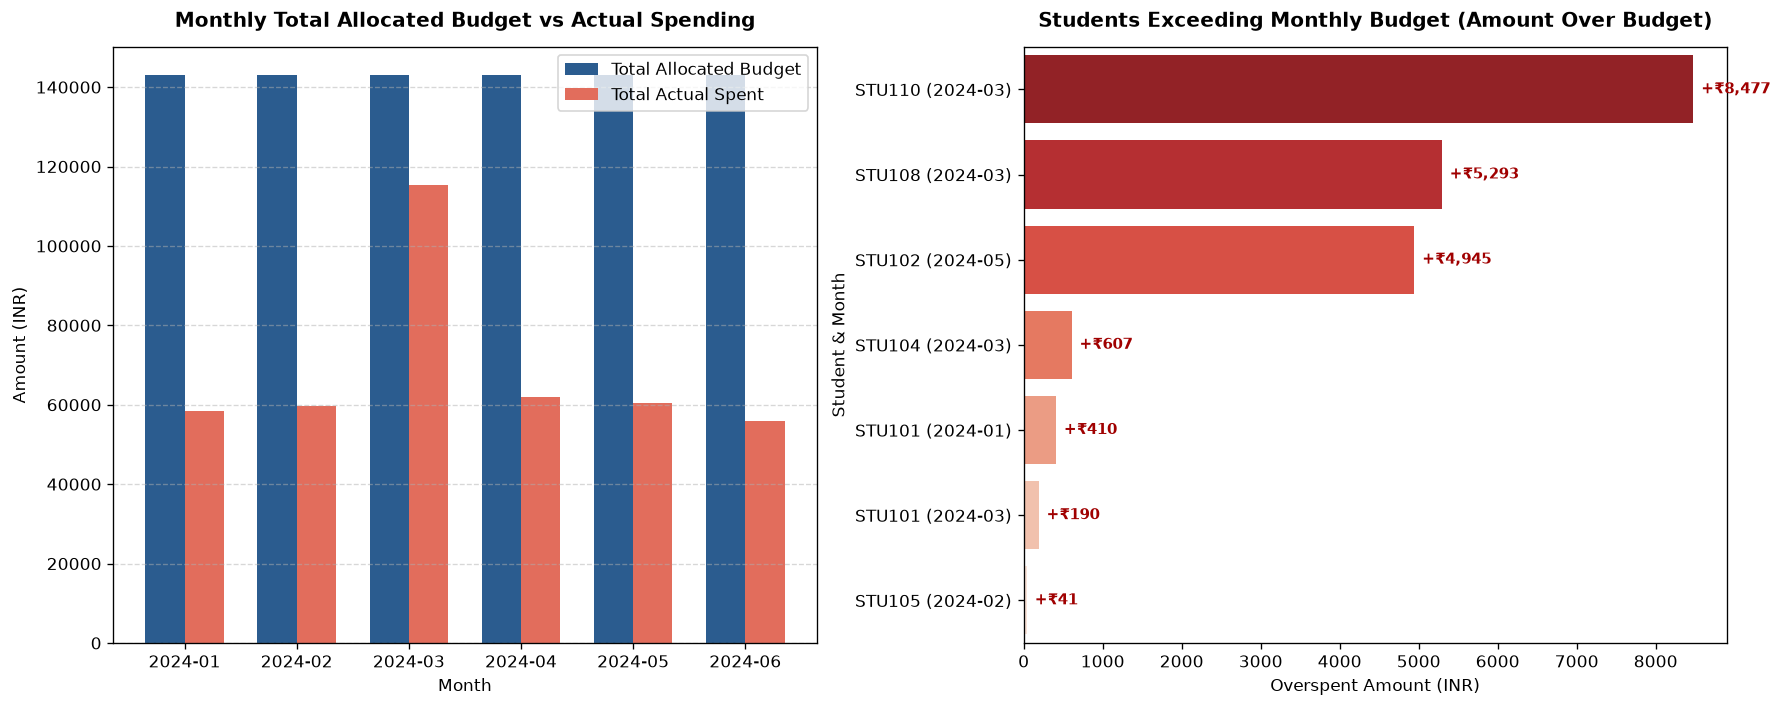

In [8]:
# Student-Month Budget Calculation
student_month = df.groupby(['Month', 'Student ID', 'Monthly Budget', 'Student Year']).agg(
    Actual_Spent=('Amount', 'sum'),
    Transactions=('Amount', 'count')
).reset_index()

student_month['Budget_Utilization'] = ((student_month['Actual_Spent'] / student_month['Monthly Budget']) * 100).round(2)
student_month['Over_Budget'] = student_month['Actual_Spent'] > student_month['Monthly Budget']
student_month['Overspend_Amount'] = (student_month['Actual_Spent'] - student_month['Monthly Budget'])

over_budget_df = student_month[student_month['Over_Budget']].sort_values(by='Overspend_Amount', ascending=False).reset_index(drop=True)

# Monthly Aggregation
monthly_budget_agg = student_month.groupby('Month').agg(
    Total_Budget=('Monthly Budget', 'sum'),
    Total_Spent=('Actual_Spent', 'sum'),
    Over_Budget_Students=('Over_Budget', 'sum')
).reset_index()
monthly_budget_agg['Overall_Utilization_%'] = ((monthly_budget_agg['Total_Spent'] / monthly_budget_agg['Total_Budget']) * 100).round(2)

print("Monthly Budget vs Actual Totals:")
print(monthly_budget_agg.to_string(index=False))

print(f"\nTotal Student-Month Over-Budget Incidents: {len(over_budget_df)}")
print("\nDetailed Over-Budget Records:")
cols_show = ['Month', 'Student ID', 'Student Year', 'Monthly Budget', 'Actual_Spent', 'Overspend_Amount', 'Budget_Utilization']
print(over_budget_df[cols_show].to_string(index=False))

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Grouped Bar: Monthly Budget vs Actual
x = np.arange(len(monthly_budget_agg['Month']))
width = 0.35
ax1.bar(x - width/2, monthly_budget_agg['Total_Budget'], width, label='Total Allocated Budget', color='#2b5c8f')
ax1.bar(x + width/2, monthly_budget_agg['Total_Spent'], width, label='Total Actual Spent', color='#e26d5c')
ax1.set_xlabel("Month")
ax1.set_ylabel("Amount (INR)")
ax1.set_title("Monthly Total Allocated Budget vs Actual Spending", weight='bold', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(monthly_budget_agg['Month'])
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Horizontal Bar: Over-Budget Instances
over_budget_df['Label'] = over_budget_df['Student ID'] + " (" + over_budget_df['Month'] + ")"
sns.barplot(data=over_budget_df, x='Overspend_Amount', y='Label', palette='Reds_r', ax=ax2, hue='Label', legend=False)
ax2.set_title("Students Exceeding Monthly Budget (Amount Over Budget)", weight='bold', pad=12)
ax2.set_xlabel("Overspent Amount (INR)")
ax2.set_ylabel("Student & Month")
for p in ax2.patches:
    ax2.annotate(f"+₹{int(p.get_width()):,}",
                 (p.get_width() + 100, p.get_y() + p.get_height()/2),
                 ha='left', va='center', fontsize=9, weight='bold', color='#a00000')

plt.tight_layout()
plt.show()

> **Key Budget Findings:**
> 1. Overall student group budget utilization stands at **47.96%**, demonstrating that students on average remain within total allocations across the semester.
> 2. However, **7 individual student-month overruns** occurred:
>    - **STU110** in March 2024 spent **₹15,477** against a ₹7,000 budget (**221.1% utilization**, overspending by ₹8,477) due to fest participation and gear purchases.
>    - **STU108** in March 2024 spent **₹16,293** against an ₹11,000 budget (**148.1% utilization**).
>    - **STU102** in May 2024 spent **₹12,445** against a ₹7,500 budget (**165.9% utilization**) around end-of-semester projects.

---
## 8. Academic Year Comparison

We analyze how spending varies across student seniority levels: 1st Year, 2nd Year, 3rd Year, and 4th Year.

Spending by Academic Seniority:
Student Year  Total_Amount  Transaction_Count  Average_Amount  Spending_Share
    3rd Year        123090                151          815.17           29.92
    2nd Year        106960                125          855.68           25.99
    4th Year         92885                138          673.08           22.57
    1st Year         88529                106          835.18           21.52


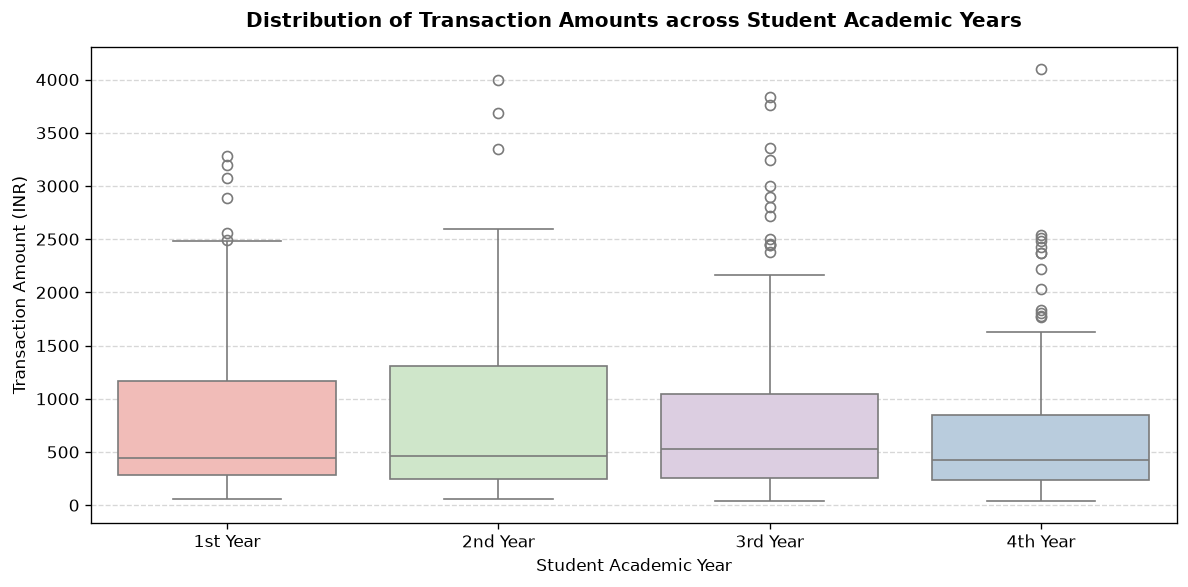

In [9]:
year_df = df.groupby('Student Year').agg(
    Total_Amount=('Amount', 'sum'),
    Transaction_Count=('Amount', 'count'),
    Average_Amount=('Amount', 'mean')
).reset_index()

year_df['Spending_Share'] = ((year_df['Total_Amount'] / total_spending) * 100).round(2)
year_df['Average_Amount'] = year_df['Average_Amount'].round(2)
year_df = year_df.sort_values(by='Total_Amount', ascending=False).reset_index(drop=True)

print("Spending by Academic Seniority:")
print(year_df.to_string(index=False))

# Visualization: Boxplot
fig, ax = plt.subplots(figsize=(10, 5))
order_years = ['1st Year', '2nd Year', '3rd Year', '4th Year']
sns.boxplot(data=df, x='Student Year', y='Amount', order=order_years, palette='Pastel1', ax=ax, hue='Student Year', legend=False)
ax.set_title("Distribution of Transaction Amounts across Student Academic Years", weight='bold', pad=12)
ax.set_ylabel("Transaction Amount (INR)")
ax.set_xlabel("Student Academic Year")
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 9. Conclusions & Practical Recommendations for Students

### Summary of Findings
1. **Discretionary Spending Leaks:** Shopping and Entertainment together constitute over **46%** of total expenditures. Moderating online impulse purchases during sales events yields the fastest savings.
2. **The "Fest Month" Effect:** March accounts for more than a quarter of all expenses across the semester. Students should set aside an emergency/fest fund starting in January to absorb high social and project expenses in March.
3. **UPI Ease vs. Frictions:** UPI's frictionless tap-to-pay creates an illusion of negligible spending on small food and snacks. Setting a daily UPI transaction ceiling or reviewing weekly passbook statements helps maintain awareness.
4. **Budget Cushioning:** 4 out of 7 over-budget events occurred among students with tighter budgets (under ₹9,000/month). Adding a 10% flexible buffer prevents minor unforeseen academic expenses (photocopies, books, project hardware) from triggering budget anxiety.

---
*Notebook completed for Student Expense Tracker analytics module.*